# 05 - Comparación de modelos

**Curso:** BD-151 Inteligencia Artificial Aplicada · **Proyecto D:** Sistema de Predicción de Calidad de Vino

**Objetivo:** comparar las configuraciones probadas en cada modelo, analizar sus curvas de pérdida y métricas, **seleccionar la mejor configuración de cada uno** y justificar las decisiones.

| Modelo | Tarea | Notebook | Métrica principal |
|---|---|---|---|
| Modelo 1 | Regresión: puntuación de calidad (0-10) | `03_ANN_Modelo1.ipynb` | MAE / RMSE |
| Modelo 2 | Clasificación binaria: calidad alta (≥ 7) Sí/No | `04_ANN_Modelo2.ipynb` | F1-score de la clase "alta" |

**Cómo se elige la mejor configuración.** Siempre con el conjunto de **validación** (no con el de prueba), para que la evaluación final siga siendo honesta. El conjunto de prueba solo se usa para reportar el rendimiento de lo ya elegido. Los dos modelos se evalúan sobre **los mismos vinos de prueba**.

**Empate técnico.** Si varias configuraciones quedan separadas por una diferencia mínima (menor que una tolerancia que se define abajo), esa diferencia está dentro del ruido del entrenamiento y no sirve para decidir. En ese caso se prefiere, en el Modelo 1, la red **más simple** (menos parámetros) y, en el Modelo 2, la de **mayor precision** (menos falsas alarmas). Poniendo la tolerancia en 0 se elige siempre la mejor métrica pura.

**Antes de ejecutar:** este notebook no entrena nada, solo lee los resultados que dejan los notebooks 03 y 04 en `models/` y `reports/metrics/`. Hay que haber ejecutado ambos primero.

# 1. Importación de librerías y configuración

In [1]:
import sys, json, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------------------------
# Raíz del proyecto (la carpeta que contiene src/config.py).
# Normalmente se detecta sola. Si el notebook está FUERA del repositorio,
# escribe aquí la ruta de tu repo, por ejemplo:
#   PROJECT_ROOT = r"C:\Users\tu_usuario\Desktop\Proyecto-D-Sistema-de-Prediccion-de-Calidad-de-Vino"
# ---------------------------------------------------------------------------
PROJECT_ROOT = None

if PROJECT_ROOT:
    ROOT = Path(PROJECT_ROOT)
else:
    ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists()), None)

if ROOT is None or not (ROOT / "src" / "config.py").exists():
    raise FileNotFoundError(
        "No se encontró src/config.py.\n"
        f"  Carpeta de trabajo actual: {Path.cwd()}\n"
        f"  Raíz probada: {ROOT}\n"
        "Solución: mueve el notebook a la carpeta notebooks/ del repositorio, "
        "o escribe la ruta del repo en PROJECT_ROOT (arriba)."
    )
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import ProjectConfig

from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score, confusion_matrix)
from tensorflow import keras

sns.set_theme(style="whitegrid")
ProjectConfig.create_directories()

MODELS_DIR  = ProjectConfig.MODELS_DIR
FIGURES_DIR = ProjectConfig.FIGURES_DIR
METRICS_DIR = ProjectConfig.REPORTS_DIR / "metrics"
print("Raíz del proyecto:", ROOT)

# ---------------------------------------------------------------------------
# Decisiones manuales (opcional). Con None se elige automáticamente la mejor
# configuración según VALIDACIÓN. Si tras leer la justificación prefieres otra,
# escribe su nombre aquí (por ejemplo: MODELO1_ELEGIDO = "B_dropout_0.2").
# ---------------------------------------------------------------------------
MODELO1_ELEGIDO = None
MODELO2_ELEGIDO = None
UMBRAL_ELEGIDO  = None   # umbral de decisión del Modelo 2 (None = el mejor F1 en validación)

# Tolerancias de empate técnico (0 = elegir siempre la mejor métrica pura)
TOLERANCIA_MAE = 0.01    # Modelo 1: diferencia de MAE en validación que se considera empate
TOLERANCIA_F1  = 0.02    # Modelo 2: diferencia de F1 en validación que se considera empate

def resaltar(df, mins=(), maxs=()):
    '''Tabla con el mejor valor de cada métrica resaltado (si el entorno lo permite).'''
    try:
        sty = df.style.format(precision=4)
        if mins: sty = sty.highlight_min(subset=list(mins), color="#c7e9c0")
        if maxs: sty = sty.highlight_max(subset=list(maxs), color="#c7e9c0")
        return sty
    except Exception:
        return df.round(4)

Raíz del proyecto: C:\Users\Eladrel\Desktop\Proyecto-D-Sistema-de-Prediccion-de-Calidad-de-Vino


# 2. Carga de resultados

Se leen los archivos que generaron los notebooks 03 y 04, y los datos de prueba (los mismos para ambos modelos).

In [2]:
needed = {
    "Modelo 1 (notebook 03)": [METRICS_DIR / "model1_results.csv"],
    "Modelo 2 (notebook 04)": [METRICS_DIR / "model2_results.csv"],
}
missing = [f"{k}: {p.name}" for k, ps in needed.items() for p in ps if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Faltan resultados en reports/metrics/:\n  - " + "\n  - ".join(missing) +
        "\nEjecuta primero el notebook 03 (genera los del Modelo 1) y el notebook 04 "
        "con la celda de exportación al final (genera los del Modelo 2)."
    )

# Modelo 1 (regresión)
res1 = pd.read_csv(METRICS_DIR / "model1_results.csv", index_col=0)
cfgs1 = [c for c in res1.index if c != "Base (promedio)"]
hist1 = {c: pd.read_csv(METRICS_DIR / f"model1_history_{c}.csv") for c in cfgs1}

# Modelo 2 (clasificación)
res2 = pd.read_csv(METRICS_DIR / "model2_results.csv").set_index("config")
cfgs2 = list(res2.index)
hist2 = {c: pd.read_csv(METRICS_DIR / f"model2_history_{c}.csv") for c in cfgs2}

# Datos (ya escalados, notebook 02)
X_train = pd.read_csv(ProjectConfig.X_TRAIN_FILE)
X_test  = pd.read_csv(ProjectConfig.X_TEST_FILE)
y_train_clf = pd.read_csv(ProjectConfig.Y_TRAIN_CLASSIFICATION_FILE).squeeze("columns")
y_test_clf  = pd.read_csv(ProjectConfig.Y_TEST_CLASSIFICATION_FILE).squeeze("columns")
y_test_reg  = pd.read_csv(ProjectConfig.Y_TEST_REGRESSION_FILE)["quality"]

print(f"Modelo 1: {len(cfgs1)} configuraciones | Modelo 2: {len(cfgs2)} configuraciones")
print(f"Vinos de prueba: {len(X_test)} | Calidad alta (≥7) en prueba: {int(y_test_clf.sum())} ({y_test_clf.mean():.1%})")

Modelo 1: 3 configuraciones | Modelo 2: 8 configuraciones
Vinos de prueba: 1064 | Calidad alta (≥7) en prueba: 202 (19.0%)


# 3. Modelo 1 (Regresión): comparación de configuraciones

Las tres configuraciones se entrenaron en el notebook 03 con la misma semilla, el mismo split y `EarlyStopping`. Solo cambian la arquitectura y el Dropout:

- **A:** 64-32 neuronas, sin Dropout.
- **B:** 64-32 neuronas, con Dropout 0.2.
- **C:** 128-64-32 neuronas, con Dropout 0.2.

## 3.1 Métricas
**MAE** y **RMSE** son errores (menor es mejor); **R²** es la variabilidad explicada (mayor es mejor). `MAE_val` es el error en validación y es el que se usa para elegir.

In [3]:
cols1 = [c for c in ["MAE", "RMSE", "R2", "Var_explicada", "Épocas", "Parámetros", "MAE_val"] if c in res1.columns]
resaltar(res1[cols1], mins=["MAE", "RMSE", "MAE_val"], maxs=["R2"])

,MAE,RMSE,R2,Var_explicada,Épocas,Parámetros,MAE_val
Configuración,,,,,,,
Base (promedio),0.6708,0.8498,-0.0012,0.0000,0,0,NaN
A_sin_dropout,0.5427,0.6999,0.3207,0.3208,40,2945,0.5665
B_dropout_0.2,0.5193,0.6610,0.3941,0.3982,170,2945,0.5443
C_profunda_drop,0.5221,0.6662,0.3845,0.3964,71,12033,0.5514


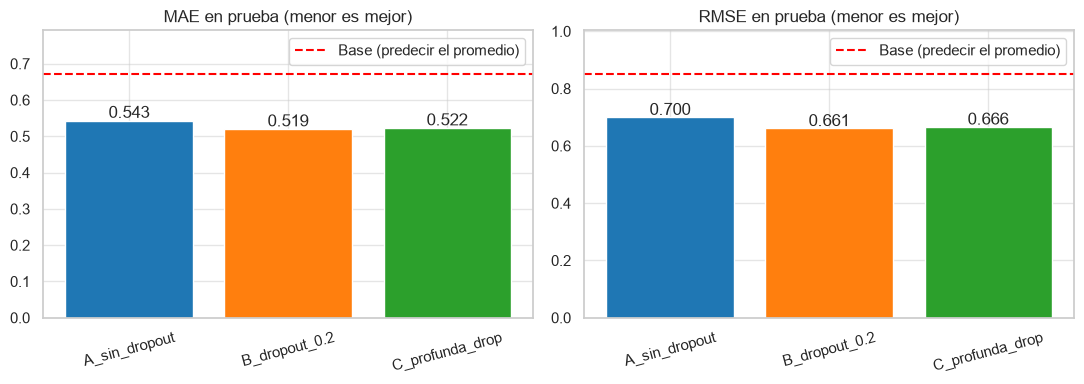

In [4]:
colors1 = dict(zip(cfgs1, sns.color_palette("tab10", len(cfgs1))))
base = res1.loc["Base (promedio)"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    vals = res1.loc[cfgs1, metric]
    ax.bar(cfgs1, vals, color=[colors1[c] for c in cfgs1])
    ax.axhline(base[metric], color="red", linestyle="--", label="Base (predecir el promedio)")
    for i, v in enumerate(vals):
        ax.text(i, v + 0.008, f"{v:.3f}", ha="center")
    ax.set_title(f"{metric} en prueba (menor es mejor)")
    ax.set_ylim(0, max(vals.max(), base[metric]) * 1.18)
    ax.tick_params(axis="x", rotation=15); ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparacion_modelo1_metricas.png", dpi=150, bbox_inches="tight")
plt.show()

## 3.2 Curvas de pérdida

Se comparan las curvas de las tres configuraciones. Qué mirar:

- Si la pérdida de **validación** sube mientras la de entrenamiento baja, hay sobreajuste.
- Con **Dropout** la pérdida de *entrenamiento* se mide con neuronas apagadas, por eso suele verse **más alta** que la de validación (que se mide sin Dropout). No es un error.

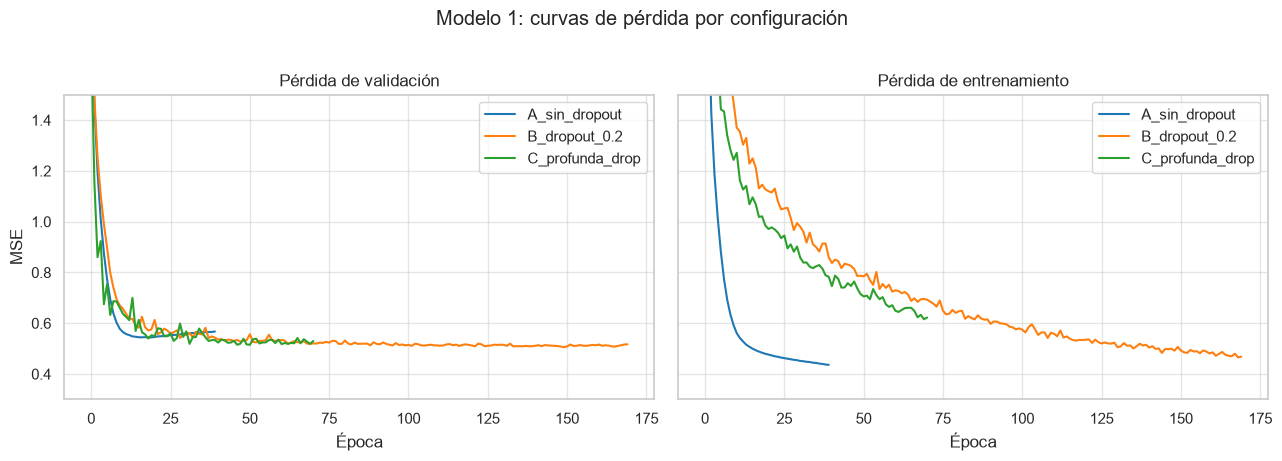

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for cfg, h in hist1.items():
    axes[0].plot(h["val_loss"], color=colors1[cfg], label=cfg)
    axes[1].plot(h["loss"],     color=colors1[cfg], label=cfg)
axes[0].set_title("Pérdida de validación"); axes[1].set_title("Pérdida de entrenamiento")
for ax in axes:
    ax.set_ylim(0.3, 1.5); ax.set_xlabel("Época"); ax.legend()   # zoom: la 1ª época (~12) aplasta la escala
axes[0].set_ylabel("MSE")
plt.suptitle("Modelo 1: curvas de pérdida por configuración", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparacion_modelo1_curvas.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# Diagnóstico numérico en la mejor época de cada configuración
diag1 = []
for cfg, h in hist1.items():
    b = int(h["val_loss"].idxmin())
    diag1.append({
        "Configuración": cfg,
        "Épocas ejecutadas": len(h),
        "Mejor época": b + 1,
        "Pérdida entrenamiento": h.loc[b, "loss"],
        "Pérdida validación": h.loc[b, "val_loss"],
        "Brecha (val - train)": h.loc[b, "val_loss"] - h.loc[b, "loss"],
    })
diag1 = pd.DataFrame(diag1).set_index("Configuración")
resaltar(diag1, mins=["Pérdida validación"])

,Épocas ejecutadas,Mejor época,Pérdida entrenamiento,Pérdida validación,Brecha (val - train)
Configuración,,,,,
A_sin_dropout,40,20,0.4796,0.5442,0.0646
B_dropout_0.2,170,150,0.5067,0.5054,-0.0012
C_profunda_drop,71,51,0.7055,0.5151,-0.1904


## 3.3 Selección de la mejor configuración y justificación

In [7]:
cand1 = res1.loc[cfgs1]
mejor_val1 = cand1["MAE_val"].min()
pura1 = cand1["MAE_val"].idxmin()
empate1 = cand1[cand1["MAE_val"] <= mejor_val1 + TOLERANCIA_MAE]
sel1 = MODELO1_ELEGIDO or empate1["Parámetros"].idxmin()
r1 = cand1.loc[sel1]
mejor_test1 = cand1["MAE"].idxmin()

print(f"Mejor MAE en validación (métrica pura): {pura1} ({mejor_val1:.3f})")
if len(empate1) > 1:
    print(f"Empate técnico (MAE_val a ≤ {TOLERANCIA_MAE} del mejor): {', '.join(empate1.index)}")
    print("  -> se elige la más simple (menos parámetros).")
print(f"Configuración elegida: {sel1}")
print(f"  Prueba -> MAE {r1['MAE']:.3f} | RMSE {r1['RMSE']:.3f} | R² {r1['R2']:.3f}")
print(f"  Mejora frente al modelo base: MAE {1 - r1['MAE']/base['MAE']:.1%} menor, RMSE {1 - r1['RMSE']/base['RMSE']:.1%} menor")
print(f"  Brecha entrenamiento-validación: {diag1.loc[sel1, 'Brecha (val - train)']:+.3f}")
print()
orden = cand1.sort_values("MAE_val")
print("Ranking por validación (MAE_val):", " > ".join(f"{c} ({v:.3f})" for c, v in orden["MAE_val"].items()))
dif = (cand1["MAE"].max() - cand1["MAE"].min())
print(f"Diferencia de MAE en prueba entre la mejor y la peor configuración: {dif:.3f} puntos de calidad")
if mejor_test1 != sel1:
    print(f"Nota: en prueba la mejor habría sido {mejor_test1}, pero la diferencia con {sel1} es de solo "
          f"{r1['MAE'] - cand1.loc[mejor_test1, 'MAE']:.3f} puntos; se mantiene la elegida por validación.")

Mejor MAE en validación (métrica pura): B_dropout_0.2 (0.544)
Empate técnico (MAE_val a ≤ 0.01 del mejor): B_dropout_0.2, C_profunda_drop
  -> se elige la más simple (menos parámetros).
Configuración elegida: B_dropout_0.2
  Prueba -> MAE 0.519 | RMSE 0.661 | R² 0.394
  Mejora frente al modelo base: MAE 22.6% menor, RMSE 22.2% menor
  Brecha entrenamiento-validación: -0.001

Ranking por validación (MAE_val): B_dropout_0.2 (0.544) > C_profunda_drop (0.551) > A_sin_dropout (0.566)
Diferencia de MAE en prueba entre la mejor y la peor configuración: 0.023 puntos de calidad


**Justificación (completar con tus palabras a partir de los resultados de arriba):**

- Qué configuración se eligió y con qué criterio (menor MAE en validación).
- Qué efecto tuvo el Dropout (¿redujo el sobreajuste? ¿mejoró el MAE?) y qué efecto tuvo la profundidad de la red (¿valió la pena tener más parámetros?).
- Qué tan buena es la mejora frente al modelo base y qué significa en puntos de calidad.
- Limitación: la calidad se concentra en 5 y 6, así que el modelo falla más en las calidades extremas.

# 4. Modelo 2 (Clasificación): comparación de configuraciones

El Modelo 2 predice si un vino es de **calidad alta (≥ 7)**. Solo ~19 % de los vinos lo son, por eso la **accuracy engaña**: un modelo que dijera siempre "no alta" acertaría ~81 %. Se compara con **precision, recall y F1 de la clase "alta"**:

- **Precision:** de los vinos que el modelo marca como altos, qué proporción lo es de verdad.
- **Recall:** de los vinos de calidad alta que existen, qué proporción logra encontrar.
- **F1:** equilibrio entre ambas (es el criterio de selección).

Las configuraciones (notebook 04) combinan tres cosas: qué **variables** usan (las 12, o las 6 elegidas por correlación), la **arquitectura** (12-6, 6-3 o 16-8, con o sin Dropout) y el manejo del desbalance con **`class_weight`**.

## 4.1 Descripción y métricas

In [8]:
resaltar_desc = res2[["variables", "n_variables", "arquitectura", "dropout", "class_weight", "epocas", "parametros"]]
resaltar_desc

,variables,n_variables,arquitectura,dropout,class_weight,epocas,parametros
config,,,,,,,
A_todas_12-6,todas,12,12-6,0.0,ninguno,30,241
B_todas_12-6_drop0.5,todas,12,12-6,0.5,ninguno,90,241
C_todas_16-8,todas,12,16-8,0.0,ninguno,49,353
D_sel_6-3,sel,6,6-3,0.0,ninguno,100,67
E_sel_6-3_drop0.5,sel,6,6-3,0.5,ninguno,48,67
F_sel_16-8,sel,6,16-8,0.0,ninguno,66,257
G_todas_16-8_cw_moderado,todas,12,16-8,0.0,"{0: 1.0, 1: 2.0}",61,353
H_todas_16-8_cw_equilibrado,todas,12,16-8,0.0,"{0: 0.6200364298724954, 1: 2.582701062215478}",73,353


In [9]:
metricas2 = res2[["val_acc", "val_precision", "val_recall", "val_f1", "test_acc", "test_precision", "test_recall", "test_f1"]].copy()
metricas2.columns = pd.MultiIndex.from_tuples(
    [("Validación", "Accuracy"), ("Validación", "Precision"), ("Validación", "Recall"), ("Validación", "F1"),
     ("Prueba", "Accuracy"), ("Prueba", "Precision"), ("Prueba", "Recall"), ("Prueba", "F1")])
try:
    display(metricas2.style.format(precision=4)
            .highlight_max(subset=[("Validación", "F1"), ("Prueba", "F1")], color="#c7e9c0"))
except Exception:
    display(metricas2.round(4))

Validación                             Prueba  \
                              Accuracy Precision  Recall      F1 Accuracy   
config                                                                      
A_todas_12-6                    0.8498    0.6087  0.3784  0.4667   0.8336   
B_todas_12-6_drop0.5            0.8275    0.6667  0.0135  0.0265   0.8148   
C_todas_16-8                    0.8486    0.5941  0.4054  0.4819   0.8374   
D_sel_6-3                       0.8462    0.6000  0.3446  0.4378   0.8158   
E_sel_6-3_drop0.5               0.8263    0.0000  0.0000  0.0000   0.8102   
F_sel_16-8                      0.8451    0.5930  0.3446  0.4359   0.8242   
G_todas_16-8_cw_moderado        0.8192    0.4835  0.5946  0.5333   0.8120   
H_todas_16-8_cw_equilibrado     0.7770    0.4239  0.7905  0.5519   0.7697   

                                                       
                            Precision  Recall      F1  
config                                                 
A_todas_12-6                   0.6106  0.3416  0.4381  
B_todas_12-6_drop0.5           0.8571  0.0297  0.0574  
C_todas_16-8                   0.6074  0.4059  0.4866  
D_sel_6-3                      0.5300  0.2624  0.3510  
E_sel_6-3_drop0.5              0.0000  0.0000  0.0000  
F_sel_16-8                     0.5728  0.2921  0.3869  
G_todas_16-8_cw_moderado       0.5040  0.6238  0.5575  
H_todas_16-8_cw_equilibrado    0.4414  0.8020  0.5694

In [10]:
colapsadas = res2.index[(res2["test_recall"] == 0)].tolist()
if colapsadas:
    print("Configuraciones que predicen SIEMPRE 'no alta' (recall = 0, no detectan ningún vino de calidad alta):")
    for c in colapsadas:
        print(f"  - {c} (dropout {res2.loc[c, 'dropout']}, accuracy {res2.loc[c, 'test_acc']:.3f}: coincide con el % de vinos 'no alta')")

Configuraciones que predicen SIEMPRE 'no alta' (recall = 0, no detectan ningún vino de calidad alta):
  - E_sel_6-3_drop0.5 (dropout 0.5, accuracy 0.810: coincide con el % de vinos 'no alta')


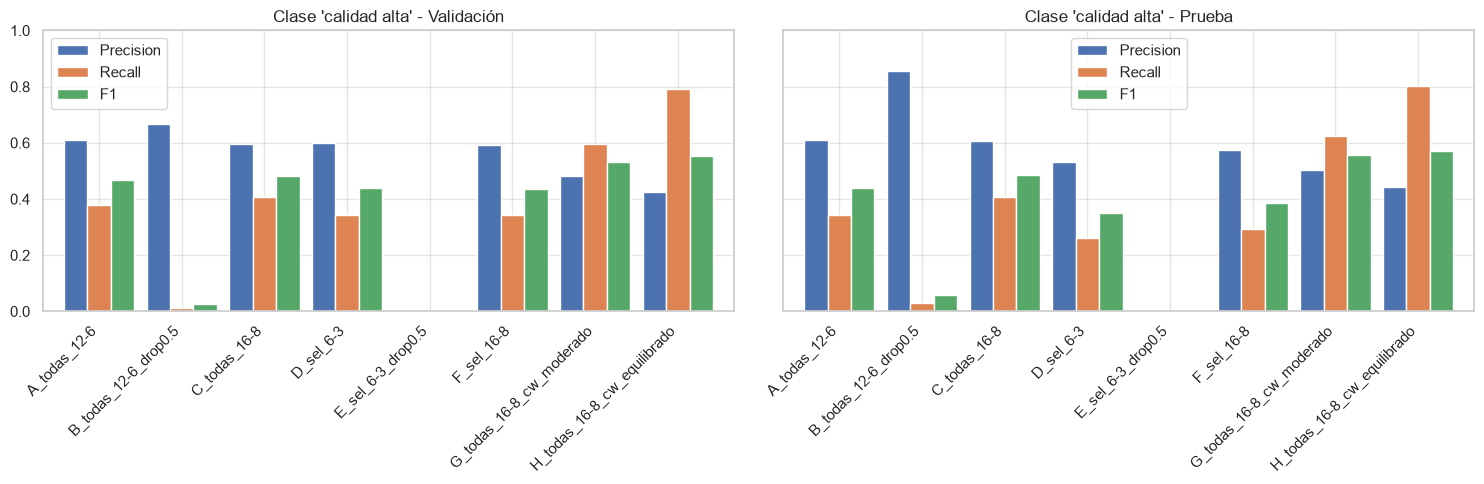

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, pref, title in zip(axes, ["val", "test"], ["Validación", "Prueba"]):
    m = res2[[f"{pref}_precision", f"{pref}_recall", f"{pref}_f1"]]
    m.columns = ["Precision", "Recall", "F1"]
    m.plot(kind="bar", ax=ax, width=0.85)
    ax.set_title(f"Clase 'calidad alta' - {title}"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparacion_modelo2_metricas.png", dpi=150, bbox_inches="tight")
plt.show()

## 4.2 Curvas de entrenamiento

Líneas continuas: variables completas (12). Líneas punteadas: variables seleccionadas (6).

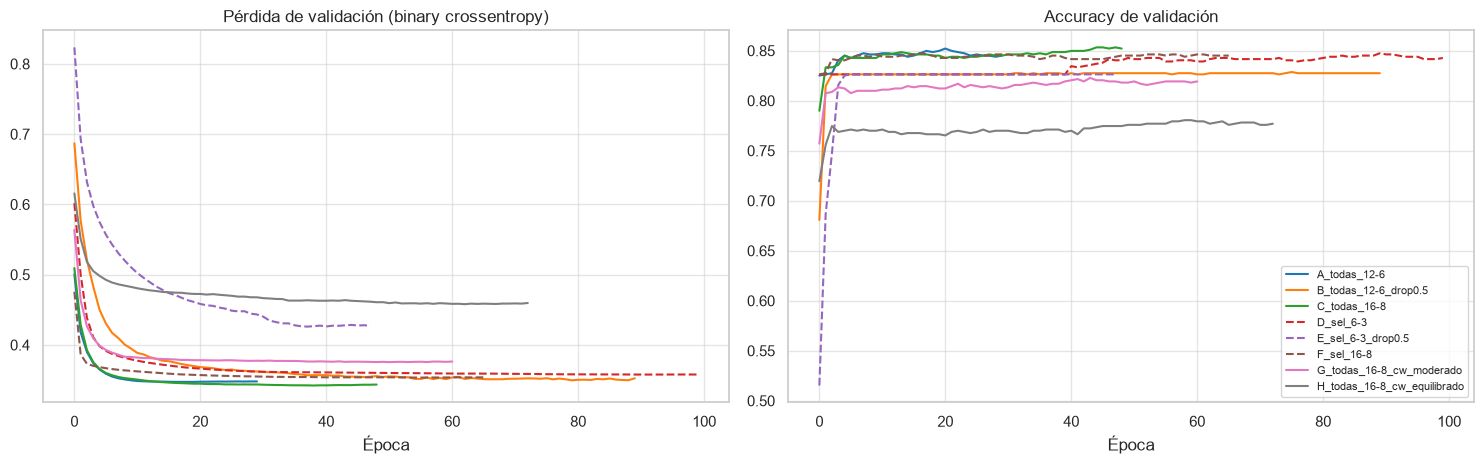

In [12]:
colors2 = dict(zip(cfgs2, sns.color_palette("tab10", len(cfgs2))))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for cfg, h in hist2.items():
    ls = "--" if res2.loc[cfg, "variables"] == "sel" else "-"
    axes[0].plot(h["val_loss"],     color=colors2[cfg], linestyle=ls, label=cfg)
    axes[1].plot(h["val_accuracy"], color=colors2[cfg], linestyle=ls, label=cfg)
axes[0].set_title("Pérdida de validación (binary crossentropy)")
axes[1].set_title("Accuracy de validación")
for ax in axes: ax.set_xlabel("Época")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparacion_modelo2_curvas.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
diag2 = []
for cfg, h in hist2.items():
    b = int(h["val_loss"].idxmin())
    diag2.append({
        "Configuración": cfg, "Épocas ejecutadas": len(h), "Mejor época": b + 1,
        "Pérdida entrenamiento": h.loc[b, "loss"], "Pérdida validación": h.loc[b, "val_loss"],
        "Brecha (val - train)": h.loc[b, "val_loss"] - h.loc[b, "loss"],
    })
diag2 = pd.DataFrame(diag2).set_index("Configuración")
resaltar(diag2, mins=["Pérdida validación"])

,Épocas ejecutadas,Mejor época,Pérdida entrenamiento,Pérdida validación,Brecha (val - train)
Configuración,,,,,
A_todas_12-6,30,20,0.3568,0.3473,-0.0094
B_todas_12-6_drop0.5,90,80,0.3981,0.3496,-0.0486
C_todas_16-8,49,39,0.3438,0.3422,-0.0016
D_sel_6-3,100,92,0.3776,0.3578,-0.0198
E_sel_6-3_drop0.5,48,38,0.4661,0.4260,-0.0400
F_sel_16-8,66,56,0.3684,0.3535,-0.0149
G_todas_16-8_cw_moderado,61,51,0.4884,0.3755,-0.1130
H_todas_16-8_cw_equilibrado,73,63,0.4341,0.4580,0.0238


## 4.3 Matrices de confusión en el conjunto de prueba

Filas = valor real, columnas = predicción. La celda inferior izquierda son los **vinos de calidad alta que el modelo no detectó** (falsos negativos).

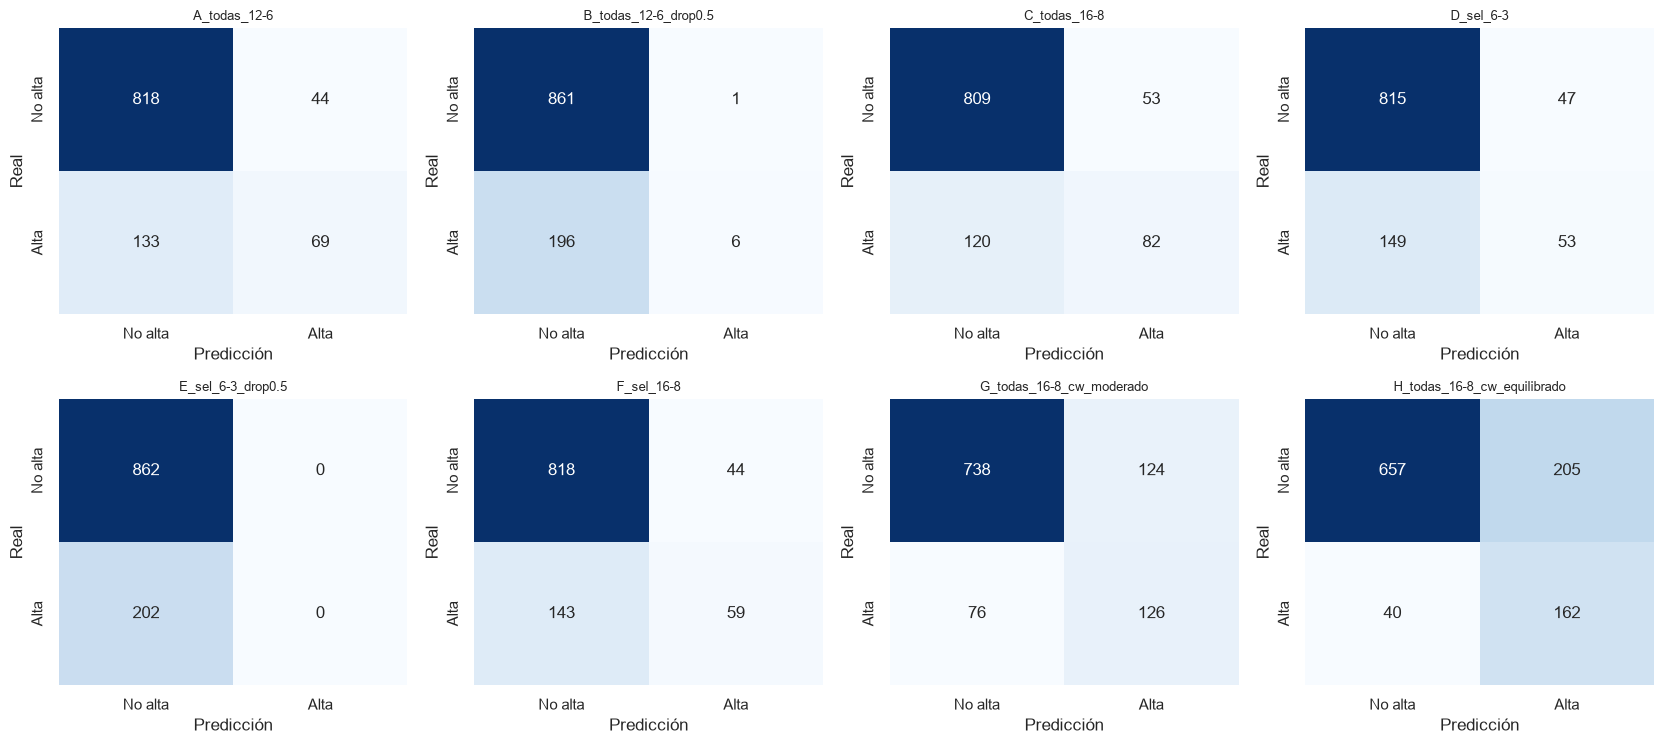

In [14]:
n = len(cfgs2)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.8 * nrows))
for ax, cfg in zip(np.ravel(axes), cfgs2):
    r = res2.loc[cfg]
    cm = np.array([[r["test_tn"], r["test_fp"]], [r["test_fn"], r["test_tp"]]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No alta", "Alta"], yticklabels=["No alta", "Alta"])
    ax.set_title(cfg, fontsize=9); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
for ax in np.ravel(axes)[n:]:
    ax.axis("off")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparacion_modelo2_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

## 4.4 Efecto del manejo del desbalance (`class_weight`)

Para aislar el efecto de `class_weight` se comparan las configuraciones que tienen **la misma arquitectura (16-8) y las mismas variables (las 12)** y solo difieren en el peso de las clases. Dar más peso a la clase "alta" suele **subir el recall a costa de la precision**.

In [15]:
mismo = res2[(res2["arquitectura"] == "16-8") & (res2["variables"] == "todas")]
efecto = mismo[["class_weight", "val_precision", "val_recall", "val_f1", "val_acc",
                "test_precision", "test_recall", "test_f1", "test_acc"]]
display(resaltar(efecto, maxs=["val_f1", "test_f1"]))

sin = mismo[mismo["class_weight"] == "ninguno"]
if len(sin):
    ref = sin.iloc[0]
    for cfg, r in mismo.iterrows():
        if cfg == sin.index[0]:
            continue
        print(f"{cfg}: respecto a no usar class_weight -> recall {r['val_recall'] - ref['val_recall']:+.1%}, "
              f"precision {r['val_precision'] - ref['val_precision']:+.1%}, F1 {r['val_f1'] - ref['val_f1']:+.3f} (validación)")

,class_weight,val_precision,val_recall,val_f1,val_acc,test_precision,test_recall,test_f1,test_acc
config,,,,,,,,,
C_todas_16-8,ninguno,0.5941,0.4054,0.4819,0.8486,0.6074,0.4059,0.4866,0.8374
G_todas_16-8_cw_moderado,"{0: 1.0, 1: 2.0}",0.4835,0.5946,0.5333,0.8192,0.5040,0.6238,0.5575,0.8120
H_todas_16-8_cw_equilibrado,"{0: 0.6200364298724954, 1: 2.582701062215478}",0.4239,0.7905,0.5519,0.7770,0.4414,0.8020,0.5694,0.7697


G_todas_16-8_cw_moderado: respecto a no usar class_weight -> recall +18.9%, precision -11.1%, F1 +0.051 (validación)
H_todas_16-8_cw_equilibrado: respecto a no usar class_weight -> recall +38.5%, precision -17.0%, F1 +0.070 (validación)


## 4.5 Selección de la mejor configuración y justificación

In [16]:
mejor_f1 = res2["val_f1"].max()
pura2 = res2["val_f1"].idxmax()
empate2 = res2[res2["val_f1"] >= mejor_f1 - TOLERANCIA_F1]
sel2 = MODELO2_ELEGIDO or empate2["val_precision"].idxmax()
r2 = res2.loc[sel2]
mejor_test2 = res2["test_f1"].idxmax()

print(f"Mejor F1 en validación (métrica pura): {pura2} ({mejor_f1:.3f})")
if len(empate2) > 1:
    print(f"Empate técnico (F1 a ≤ {TOLERANCIA_F1} del mejor): {', '.join(empate2.index)}")
    print("  -> se elige la de mayor precision (menos falsas alarmas).")
print(f"Configuración elegida: {sel2}")
print(f"  Variables: {r2['variables']} ({int(r2['n_variables'])}) | arquitectura {r2['arquitectura']} | "
      f"dropout {r2['dropout']} | class_weight {r2['class_weight']}")
print(f"  Validación -> precision {r2['val_precision']:.3f} | recall {r2['val_recall']:.3f} | F1 {r2['val_f1']:.3f}")
print(f"  Prueba     -> precision {r2['test_precision']:.3f} | recall {r2['test_recall']:.3f} | F1 {r2['test_f1']:.3f} | accuracy {r2['test_acc']:.3f}")
print()
orden = res2.sort_values("val_f1", ascending=False)
print("Ranking por F1 en validación:")
for c, v in orden["val_f1"].items():
    print(f"  {c:30s} {v:.3f}")
if mejor_test2 != sel2:
    print(f"\nNota: en prueba el mejor F1 es {mejor_test2} ({res2.loc[mejor_test2, 'test_f1']:.3f}) frente a "
          f"{res2.loc[sel2, 'test_f1']:.3f} de la elegida. Se mantiene la elegida por validación para no ajustar la decisión al conjunto de prueba.")

Mejor F1 en validación (métrica pura): H_todas_16-8_cw_equilibrado (0.552)
Empate técnico (F1 a ≤ 0.02 del mejor): G_todas_16-8_cw_moderado, H_todas_16-8_cw_equilibrado
  -> se elige la de mayor precision (menos falsas alarmas).
Configuración elegida: G_todas_16-8_cw_moderado
  Variables: todas (12) | arquitectura 16-8 | dropout 0.0 | class_weight {0: 1.0, 1: 2.0}
  Validación -> precision 0.484 | recall 0.595 | F1 0.533
  Prueba     -> precision 0.504 | recall 0.624 | F1 0.558 | accuracy 0.812

Ranking por F1 en validación:
  H_todas_16-8_cw_equilibrado    0.552
  G_todas_16-8_cw_moderado       0.533
  C_todas_16-8                   0.482
  A_todas_12-6                   0.467
  D_sel_6-3                      0.438
  F_sel_16-8                     0.436
  B_todas_12-6_drop0.5           0.026
  E_sel_6-3_drop0.5              0.000

Nota: en prueba el mejor F1 es H_todas_16-8_cw_equilibrado (0.569) frente a 0.558 de la elegida. Se mantiene la elegida por validación para no ajustar la de

**Justificación (completar con tus palabras a partir de los resultados de arriba):**

- Por qué el F1 de la clase "alta" y no la accuracy (desbalance de clases).
- Si usar las 6 variables seleccionadas fue mejor o peor que usar las 12.
- Qué hizo `class_weight` (sube el recall, baja la precision) y por qué se acepta ese intercambio en control de calidad: es más grave **no detectar** un lote de calidad alta que revisar uno de más.
- Qué efecto tuvo el Dropout 0.5 en estas redes pequeñas.

## 4.6 Umbral de decisión

La red devuelve una probabilidad. Por defecto se clasifica como "alta" si es ≥ 0.5, pero con clases desbalanceadas otro umbral puede dar un mejor equilibrio entre precision y recall. El umbral se busca **con validación** y luego se comprueba en prueba.

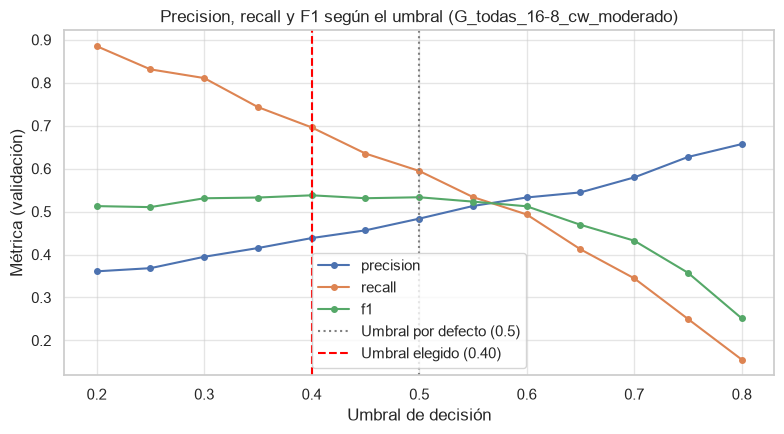

In [17]:
split_at = int(len(X_train) * 0.8)        # misma partición de validación que usó el notebook 04
feats2 = res2.loc[sel2, "features"].split("|")
modelo2 = keras.models.load_model(MODELS_DIR / f"model2_{sel2}.keras")

y_val_clf = y_train_clf.iloc[split_at:]
p_val  = modelo2.predict(X_train.iloc[split_at:][feats2], verbose=0).ravel()
p_test = modelo2.predict(X_test[feats2], verbose=0).ravel()

umbrales = np.round(np.arange(0.20, 0.801, 0.05), 2)
curva = pd.DataFrame([{
    "umbral": t,
    "precision": precision_score(y_val_clf, p_val >= t, zero_division=0),
    "recall":    recall_score(y_val_clf, p_val >= t, zero_division=0),
    "f1":        f1_score(y_val_clf, p_val >= t, zero_division=0),
} for t in umbrales]).set_index("umbral")

best_thr = float(curva["f1"].idxmax())
UMBRAL = float(UMBRAL_ELEGIDO) if UMBRAL_ELEGIDO is not None else best_thr

fig, ax = plt.subplots(figsize=(8, 4.5))
curva.plot(ax=ax, marker="o", ms=4)
ax.axvline(0.5, color="gray", linestyle=":", label="Umbral por defecto (0.5)")
ax.axvline(UMBRAL, color="red", linestyle="--", label=f"Umbral elegido ({UMBRAL:.2f})")
ax.set_xlabel("Umbral de decisión"); ax.set_ylabel("Métrica (validación)")
ax.set_title(f"Precision, recall y F1 según el umbral ({sel2})"); ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "comparacion_modelo2_umbral.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
def metricas_clf(y_true, proba, thr):
    pred = (np.asarray(proba) >= thr).astype(int)
    return {"Umbral": thr,
            "Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0)}

comp_umbral = pd.DataFrame([
    {"Conjunto": "Validación", **metricas_clf(y_val_clf, p_val, 0.5)},
    {"Conjunto": "Validación", **metricas_clf(y_val_clf, p_val, UMBRAL)},
    {"Conjunto": "Prueba",     **metricas_clf(y_test_clf, p_test, 0.5)},
    {"Conjunto": "Prueba",     **metricas_clf(y_test_clf, p_test, UMBRAL)},
]).set_index(["Conjunto", "Umbral"])
display(comp_umbral.round(4))

f_a = metricas_clf(y_test_clf, p_test, 0.5)["F1"]; f_b = metricas_clf(y_test_clf, p_test, UMBRAL)["F1"]
print(f"Umbral elegido con validación: {UMBRAL:.2f}")
print(f"F1 en prueba: {f_a:.3f} (umbral 0.50) -> {f_b:.3f} (umbral {UMBRAL:.2f})")
if abs(UMBRAL - 0.5) < 1e-9:
    print("El umbral por defecto ya era el mejor en validación: no se cambia.")
elif f_b < f_a:
    print("Atención: el umbral elegido en validación NO mejoró el F1 en prueba. Conviene mantener 0.50 "
          "(escribe UMBRAL_ELEGIDO = 0.5 arriba) o justificar el cambio por otras razones.")

Accuracy  Precision  Recall      F1
Conjunto   Umbral                                     
Validación 0.5       0.8192     0.4835  0.5946  0.5333
           0.4       0.7923     0.4383  0.6959  0.5379
Prueba     0.5       0.8120     0.5040  0.6238  0.5575
           0.4       0.7867     0.4618  0.7475  0.5709

Umbral elegido con validación: 0.40
F1 en prueba: 0.558 (umbral 0.50) -> 0.571 (umbral 0.40)


# 5. Comparación entre los dos modelos seleccionados

Los dos modelos responden preguntas distintas (valor numérico frente a Sí/No), así que **sus métricas no son comparables entre sí**. Sí se puede responder a esta pregunta: *¿hace falta el Modelo 2, o basta con usar el Modelo 1 y decir "alta" cuando predice ≥ 6.5?* Para eso se usa el Modelo 1 como si fuera un clasificador.

In [19]:
m1 = keras.models.load_model(MODELS_DIR / f"model1_{sel1}.keras")
pred_reg = np.clip(m1.predict(X_test, verbose=0).ravel(), 0, 10)

filas = []
for corte in [6.5, 6.0]:
    pred = (pred_reg >= corte).astype(int)
    filas.append({"Modelo": f"Modelo 1 (regresión) como clasificador, predicción ≥ {corte}",
                  "Accuracy": accuracy_score(y_test_clf, pred),
                  "Precision": precision_score(y_test_clf, pred, zero_division=0),
                  "Recall": recall_score(y_test_clf, pred, zero_division=0),
                  "F1": f1_score(y_test_clf, pred, zero_division=0)})
filas.append({"Modelo": f"Modelo 2 (clasificación), umbral {UMBRAL:.2f}", **{k: v for k, v in
              metricas_clf(y_test_clf, p_test, UMBRAL).items() if k != "Umbral"}})
cruzada = pd.DataFrame(filas).set_index("Modelo")

a65, a60, m2f = cruzada.iloc[0], cruzada.iloc[1], cruzada.iloc[2]
print(f"Con el corte natural (≥ 6.5) el Modelo 1 detecta {a65['Recall']:.1%} de los vinos de calidad alta (F1 {a65['F1']:.3f}); "
      f"el Modelo 2 detecta {m2f['Recall']:.1%} (F1 {m2f['F1']:.3f}).")
print(f"Bajando el corte a ≥ 6.0 el Modelo 1 llega a recall {a60['Recall']:.1%} y F1 {a60['F1']:.3f}, "
      f"a costa de precision {a60['Precision']:.1%} (Modelo 2: {m2f['Precision']:.1%}).")
resaltar(cruzada, maxs=["F1", "Recall"])

Con el corte natural (≥ 6.5) el Modelo 1 detecta 37.1% de los vinos de calidad alta (F1 0.453); el Modelo 2 detecta 74.8% (F1 0.571).
Bajando el corte a ≥ 6.0 el Modelo 1 llega a recall 77.7% y F1 0.558, a costa de precision 43.5% (Modelo 2: 46.2%).


,Accuracy,Precision,Recall,F1
Modelo,,,,
"Modelo 1 (regresión) como clasificador, predicción ≥ 6.5",0.8299,0.5814,0.3713,0.4532
"Modelo 1 (regresión) como clasificador, predicción ≥ 6.0",0.7660,0.4349,0.7772,0.5577
"Modelo 2 (clasificación), umbral 0.40",0.7867,0.4618,0.7475,0.5709


**Cómo leer esta tabla.** La regresión "encoge" sus predicciones hacia 5-6 y rara vez llega a 7, por eso con el corte natural detecta pocos vinos de calidad alta. Se puede compensar bajando el corte, pero ese corte hay que elegirlo a mano; el Modelo 2 aprende ese equilibrio directamente durante el entrenamiento (con `class_weight`) y devuelve una probabilidad de calidad alta. Revisa los números de arriba para ver cuánta ventaja real tiene en esta ejecución, y menciónalo con honestidad en las conclusiones.

Cada modelo cumple un papel distinto en el sistema:

- **Modelo 1:** estima la puntuación de calidad (endpoint `/predict/quality`).
- **Modelo 2:** identifica los lotes de calidad alta (endpoint `/predict/high_quality`).

## 5.1 Resumen final y archivos para la API

Se copian los modelos elegidos a los nombres que usará la API (`models/model1.keras` y `models/model2.keras`) y se guarda un archivo `model_selection.json` con todo lo que la API necesita saber: qué variables recibe cada modelo, en qué orden, el umbral del Modelo 2 y qué scaler usar.

In [20]:
# Copiar los modelos elegidos a los nombres finales
shutil.copy(MODELS_DIR / f"model1_{sel1}.keras", MODELS_DIR / "model1.keras")
shutil.copy(MODELS_DIR / f"model2_{sel2}.keras", MODELS_DIR / "model2.keras")

test2 = metricas_clf(y_test_clf, p_test, UMBRAL)
seleccion = {
    "scaler": "models/standard_scaler.joblib",
    "input_columns_scaler": list(X_train.columns),
    "modelo1": {
        "tarea": "regresion", "endpoint": "/predict/quality",
        "archivo": "models/model1.keras", "configuracion": sel1,
        "variables": list(X_train.columns), "rango_salida": [0, 10],
        "prueba": {"MAE": float(r1["MAE"]), "RMSE": float(r1["RMSE"]), "R2": float(r1["R2"])},
    },
    "modelo2": {
        "tarea": "clasificacion_binaria", "endpoint": "/predict/high_quality",
        "archivo": "models/model2.keras", "configuracion": sel2,
        "variables": feats2, "class_weight": str(r2["class_weight"]),
        "umbral": UMBRAL,
        "prueba": {k.lower(): float(v) for k, v in test2.items() if k != "Umbral"},
    },
}
with open(METRICS_DIR / "model_selection.json", "w", encoding="utf-8") as f:
    json.dump(seleccion, f, indent=2, ensure_ascii=False)

resumen = pd.DataFrame([
    {"Modelo": "Modelo 1 - Regresión", "Configuración": sel1, "Variables": len(X_train.columns),
     "Parámetros": int(r1["Parámetros"]), "Métrica principal (prueba)": f"MAE {r1['MAE']:.3f} | RMSE {r1['RMSE']:.3f} | R² {r1['R2']:.3f}",
     "Archivo": "models/model1.keras"},
    {"Modelo": "Modelo 2 - Clasificación", "Configuración": sel2, "Variables": int(r2["n_variables"]),
     "Parámetros": int(r2["parametros"]),
     "Métrica principal (prueba)": f"Precision {test2['Precision']:.3f} | Recall {test2['Recall']:.3f} | F1 {test2['F1']:.3f} (umbral {UMBRAL:.2f})",
     "Archivo": "models/model2.keras"},
]).set_index("Modelo")
resumen.to_csv(METRICS_DIR / "model_comparison_summary.csv")
resumen

,Configuración,Variables,Parámetros,Métrica principal (prueba),Archivo
Modelo,,,,,
Modelo 1 - Regresión,B_dropout_0.2,12,2945,MAE 0.519 | RMSE 0.661 | R² 0.394,models/model1.keras
Modelo 2 - Clasificación,G_todas_16-8_cw_moderado,12,353,Precision 0.462 | Recall 0.748 | F1 0.571 (umb...,models/model2.keras


In [21]:
# Verificación: los archivos finales se cargan y dan las mismas predicciones que las configuraciones elegidas
f1_ok = np.allclose(keras.models.load_model(MODELS_DIR / "model1.keras").predict(X_test, verbose=0),
                    m1.predict(X_test, verbose=0), atol=1e-5)
f2_ok = np.allclose(keras.models.load_model(MODELS_DIR / "model2.keras").predict(X_test[feats2], verbose=0).ravel(),
                    p_test, atol=1e-5)
print("model1.keras correcto:", f1_ok, "| model2.keras correcto:", f2_ok)
print("Guardado:", METRICS_DIR / "model_selection.json")

model1.keras correcto: True | model2.keras correcto: True
Guardado: C:\Users\Eladrel\Desktop\Proyecto-D-Sistema-de-Prediccion-de-Calidad-de-Vino\reports\metrics\model_selection.json


# 6. Conclusiones


**Modelo 1 (regresión)**
- Configuración elegida y justificación.
- Mejora sobre el modelo base y significado práctico del MAE.

**Modelo 2 (clasificación)**
- Configuración, variables, `class_weight` y umbral elegidos, con su justificación.
- Qué se gana y qué se pierde al priorizar el recall.

**Sobre el sistema completo**
- Cada modelo cumple un papel distinto (estimar la puntuación frente a marcar lotes de calidad alta).
- Limitaciones: desbalance de clases, calidad concentrada en 5-6 y que la calidad la asignan catadores (hay ruido en la etiqueta).
- Mejoras posibles: más datos de calidad alta, otras arquitecturas, validación cruzada.